<a href="https://colab.research.google.com/github/dung-ho03/capdyssey/blob/main/02_but_ppg_quality_cnn_%EC%88%98%EC%A0%95.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BUT PPG 신호 품질 1D-CNN — 개발 · 평가 (Colab + Drive + GitHub) · 수정본

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dung-ho03/capdyssey/blob/main/notebooks/02_but_ppg_quality_cnn.ipynb)

| 항목 | 내용 |
|---|---|
| 데이터 | BUT PPG v2.0.0 (PhysioNet, CC BY 4.0) — 50명, 10초 PPG 3,888개 |
| 입력 | PPG (스마트폰 영상 **빨간 채널** 기반), **10초 · 30Hz → 300개 값** |
| 정답 | `quality-hr-ann.csv` — **1 = 심박수 읽기 좋은 품질 / 0 = 나쁜 품질** (AF 정답 아님) |
| 연결 | 정답 CSV의 **ID** = PPG 파일의 ID (`{ID}/{ID}_PPG.dat/.hea`) |
| 분할 | **피험자 단위** (ID 앞 3자리 = 피험자) 5-fold 교차검증 → 누수 방지 |
| 주의 | 좋음 830 / 나쁨 3,058 → **모두 나쁨으로 예측해도 정확도 약 78.7%**. 정확도 대신 AUPRC·BalAcc·MCC·클래스별 지표를 봅니다. |

**실행 순서:** 0(Drive·GitHub·다운로드) → 1(설정) → 2(로드) → … 위에서 아래로.
처음 한 번은 `SMOKE_TEST = True` 로 빠르게 전체 흐름을 점검한 뒤 `False` 로 바꿔 **런타임 다시 시작 후 모두 실행**하세요.

### 이번 수정본에서 고친 것 (원인 → 수정)
1. **헤더가 깨진 레코드 48개(피험자 100~111)**: 헤더가 `300 신호 × 1 샘플`로 적혀 있어 wfdb 가 길이 1짜리 신호를 읽고, 이전 코드는 이를 `edge` 패딩으로 300개 **상수 신호**로 만들었음. 스모크 테스트가 하필 앞 12명(=이 48개)을 골라서 전부 상수 → 모델·baseline 모두 같은 확률(0.5421), AUROC 0.5.
   → `.hea` 를 직접 파싱해 두 형식을 모두 읽고, 예상 밖 형식은 **에러**로 멈춤 (조용한 패딩 제거).
2. **채널 선택**: `rec.sig_name` 이 깨져 있어 `PPG_R` 검색이 항상 실패 → 우연히 0번이 R 이었음. → 헤더 설명을 직접 읽어 `PPG_R` 을 **assert 로 확인**.
3. **캐시**: 예전 캐시(`but_ppg_300.npz`)에 쓰레기 데이터가 저장돼 있음 → 새 이름 `but_ppg_300_v2.npz` 사용.
4. **스모크 서브셋**: 앞 12명 → **무작위 12명 × 최대 24개**. `data`·`X_raw`·`y`·`groups` 가 항상 같은 샘플을 가리키도록 한 곳에서만 정함 (예전 Cell 20 삭제).
5. **NaN 은폐 제거**: `nan_to_num` 으로 덮지 않고 assert. 평평한 신호는 전처리에서 명시적으로 0 신호 처리.
6. **검증 분할**: val 에 좋음/나쁨이 모두 있도록 보장 (한쪽만 있으면 AUPRC·임계값이 무의미).
7. **스모크 BATCH**: 샘플이 적을 때 epoch 당 step 이 1번이던 문제 → 스모크는 BATCH=16.
8. **상수 출력 감지**: 예측이 거의 같은 값이면 assert 로 즉시 중단.
9. **저장 경로**: 스모크 결과는 `..._smoke` 폴더에 저장 (본 실행 결과를 덮어쓰지 않음).
10. 디버그 셀·중복 함수·`try/except + break` 제거. 어디서 실행해도 순서대로 돌아가도록 정리.

## 0. Google Drive · GitHub 연결 · 데이터 다운로드

In [ ]:
import os
from google.colab import drive
drive.mount("/content/drive")

REPO_PARENT = "/content/drive/MyDrive/Colab Notebooks"
REPO_URL    = "https://github.com/dung-ho03/capdyssey.git"
REPO_DIR    = f"{REPO_PARENT}/capdyssey"
UPDATE_REPO = False          # True: git pull (로컬에서 수정한 파일과 충돌할 수 있어 기본은 끔)

if not os.path.isdir(f"{REPO_DIR}/.git"):
    os.makedirs(REPO_PARENT, exist_ok=True)
    !git clone {REPO_URL} "{REPO_DIR}"
elif UPDATE_REPO:
    !git -C "{REPO_DIR}" pull

os.chdir(REPO_DIR)
print("작업 폴더:", os.getcwd())

# torch / numpy / scipy / matplotlib 은 Colab 기본 설치본을 그대로 사용합니다.
!python -m pip install -q -r requirements.txt wfdb scikit-learn pandas

Mounted at /content/drive
작업 폴더: /content/drive/MyDrive/Colab Notebooks/capdyssey
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.8 MB/s eta 0:00:00


In [ ]:
# BUT PPG 다운로드 (레포의 scripts/download_data.py 사용, 저장 위치: data/raw/but/)
# 최초 1회만 실행됩니다. 작은 파일이 약 2만 7천 개라 Drive에서는 시간이 걸립니다.
BUT_DIR = f"{REPO_DIR}/data/raw/but"
if not os.path.exists(f"{BUT_DIR}/download-status.json"):
    !python scripts/download_data.py but --plan
    !python scripts/download_data.py but --workers 8
else:
    print("이미 다운로드됨:", open(f"{BUT_DIR}/download-status.json").read())
assert os.path.isdir(BUT_DIR), "다운로드 실패: 위 출력의 에러 메시지를 확인하세요."

이미 다운로드됨: {
  "dataset": "but",
  "files_verified": 27125,
  "source": "https://physionet.org/content/butppg/2.0.0/",
  "license": "CC-BY-4.0"
}


## 1. 설정

In [ ]:
import glob, json, random, time, re, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from scipy.signal import butter, filtfilt
from scipy.stats import skew, kurtosis
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve, matthews_corrcoef)
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
warnings.filterwarnings("ignore", message=".*The least populated class.*")

SMOKE_TEST        = True      # True: 무작위 12명(피험자당 최대 24개), 3 epoch → 흐름 점검용 / 본 실행은 False
SMOKE_SUBJECTS    = 12
SMOKE_PER_SUBJECT = 24
FS, N_SAMPLES = 30, 300       # 30Hz x 10초
CHANNEL_NAME  = "PPG_R"       # 헤더 설명에 이 이름이 있어야 함 (assert 로 확인)
N_FOLDS       = 5
BATCH, LR     = (16 if SMOKE_TEST else 64), 1e-3
EPOCHS        = 3 if SMOKE_TEST else 60
PATIENCE      = 10
SEED          = 42
FLAT_STD      = 1e-3          # 원본 표준편차가 이보다 작으면 '평평한 신호'
REBUILD_CACHE = False         # True: 캐시 무시하고 파일 다시 읽기

CACHE_PATH = f"{REPO_DIR}/data/processed/but_ppg_300_v2.npz"      # v2: 예전 캐시(깨진 데이터)와 분리. .gitignore 대상(/data/processed/)
RESULT_DIR = f"{REPO_DIR}/models/but_quality_cnn_v1" + ("_smoke" if SMOKE_TEST else "")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| SMOKE_TEST =", SMOKE_TEST, "| BATCH =", BATCH, "| EPOCHS =", EPOCHS)

device: cuda | SMOKE_TEST = True | BATCH = 16 | EPOCHS = 3


## 2. 데이터 로드 · ID 연결
- `quality-hr-ann.csv` 의 ID 와 같은 ID 의 `*_PPG` 파일을 연결합니다. (BOM·헤더 유무 자동 처리, ID는 6자리로 보정)
- **`.hea` 를 직접 파싱합니다.** (wfdb 는 이 데이터셋의 헤더 일부를 잘못 읽음)
  - 정상 형식(3,840개): `3채널(R,G,B) × 300샘플` → R 채널 사용
  - 깨진 형식(피험자 100~111, 48개): `300채널 × 1샘플`, `.dat` 은 전부 0 이고 **값이 헤더의 채널별 gain 에 들어 있음** → `-(0-baseline)/gain` 으로 복원 (0~255 픽셀 밝기 범위로 나와 정상 R 채널과 같은 단위)
  - 그 외 형식은 에러로 중단합니다. (조용한 패딩 없음)
- 한 번 읽은 신호는 Drive 의 `data/processed/but_ppg_300_v2.npz` 에 캐시합니다.
- 피험자 = `ID[:3]`

In [ ]:
_SIG = re.compile(r"^\s*(\S+)\s+(\d+)\s+(-?[\d.eE+-]+)\((-?\d+)\)/(\S*)\s+(-?\d+)\s+(-?\d+)\s+(-?\d+)\s+(-?\d+)\s+(-?\d+)\s*(.*)$")

def read_one(item):
    """반환: (ID, 300개 값(R채널, 0~255 밝기), kind)  kind 0=정상 형식, 1=깨진 헤더 복원"""
    rid, base = item
    with open(base + ".hea", encoding="utf-8", errors="replace") as f:
        lines = [l.rstrip("\r\n") for l in f if l.strip() and not l.startswith("#")]
    h = lines[0].split(); n_sig, fs, n_samp = int(h[1]), float(h[2]), int(h[3])
    assert round(fs) == FS, f"{rid}: fs={fs}"
    sigs = [_SIG.match(l) for l in lines[1:1 + n_sig]]
    assert len(sigs) == n_sig and all(sigs), f"{rid}: 헤더 파싱 실패"
    gain = np.array([float(m[3]) for m in sigs]); bl = np.array([float(m[4]) for m in sigs])
    d = np.fromfile(base + ".dat", dtype="<i2")
    if n_sig == 3 and n_samp == N_SAMPLES:                       # 정상: 3채널 x 300샘플 (샘플 단위로 섞여 저장)
        assert sigs[0][11].strip().endswith(CHANNEL_NAME), f"{rid}: 0번 채널이 {CHANNEL_NAME} 이 아님: {sigs[0][11]!r}"
        assert d.size == n_sig * n_samp, f"{rid}: dat 크기 불일치"
        x = (d.reshape(n_samp, n_sig)[:, 0] - bl[0]) / gain[0]; kind = 0
    elif n_sig == N_SAMPLES and n_samp == 1:                     # 깨진 헤더(피험자 100~111)
        x = -((d.astype(np.float64) - bl) / gain); kind = 1
    else:
        raise ValueError(f"{rid}: 예상 못한 형식 n_sig={n_sig}, n_samp={n_samp}")
    assert len(x) == N_SAMPLES and np.isfinite(x).all(), f"{rid}: 길이/값 이상"
    return rid, x.astype(np.float32), kind

def build_dataset():
    ann = glob.glob(os.path.join(BUT_DIR, "**", "quality-hr-ann.csv"), recursive=True)
    assert ann, f"{BUT_DIR} 아래에 quality-hr-ann.csv 가 없습니다. 0번 셀의 다운로드 출력을 확인하세요."
    ann_path = ann[0]; base = os.path.dirname(ann_path); print("annotation:", ann_path)

    df = pd.read_csv(ann_path, header=None, encoding="utf-8-sig")        # 파일 맨 앞에 BOM 이 있음
    if not str(df.iloc[0, 0]).strip().isdigit():                          # 첫 행이 헤더면 제거
        df = df.iloc[1:]
    df = df.iloc[:, :3].copy(); df.columns = ["ID", "quality", "HR"]
    df["ID"] = df["ID"].astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.zfill(6)
    df["quality"] = df["quality"].astype(int); df["HR"] = pd.to_numeric(df["HR"], errors="coerce")
    assert not df["ID"].duplicated().any(), "CSV 에 중복 ID 가 있습니다."

    index = {}                                                            # ID -> *_PPG 경로(확장자 제외)
    for dirpath, _, files in os.walk(base):
        for f in files:
            if f.endswith("_PPG.hea"): index[f[:-8]] = os.path.join(dirpath, f[:-4])
    print(f"CSV {len(df)}개 / PPG 파일 {len(index)}개")
    todo = [(rid, index[rid]) for rid in df["ID"] if rid in index]
    missing = [rid for rid in df["ID"] if rid not in index]
    print(f"PPG 없는 ID: {len(missing)}개", missing[:10])
    assert todo, "CSV 의 ID 와 매칭되는 PPG 파일이 없습니다."

    t0 = time.time()
    with ThreadPoolExecutor(8) as pool: out = list(pool.map(read_one, todo))
    kinds = np.array([o[2] for o in out])
    print(f"읽기 완료 {time.time()-t0:.0f}s | 정상 형식 {int((kinds==0).sum())}개, 깨진 헤더 복원 {int((kinds==1).sum())}개")
    got = {o[0]: o[1] for o in out}; kind_of = {o[0]: o[2] for o in out}
    df = df[df["ID"].isin(got)].reset_index(drop=True)
    df["hdr_fixed"] = [kind_of[r] for r in df["ID"]]
    X_raw = np.stack([got[r] for r in df["ID"]])
    return df, X_raw

def load_but():
    if os.path.exists(CACHE_PATH) and not REBUILD_CACHE:
        z = np.load(CACHE_PATH, allow_pickle=False); print("캐시 사용:", CACHE_PATH)
        return pd.DataFrame({"ID": z["ids"], "quality": z["y"], "HR": z["hr"], "hdr_fixed": z["kind"]}), z["X_raw"]
    df, X_raw = build_dataset()
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    np.savez_compressed(CACHE_PATH, ids=np.asarray(df["ID"].tolist(), dtype="U8"), y=df["quality"].to_numpy(dtype=np.int64),
                        hr=df["HR"].to_numpy(dtype=np.float64), kind=df["hdr_fixed"].to_numpy(dtype=np.int64), X_raw=X_raw.astype(np.float32))
    print("캐시 저장:", CACHE_PATH); return df, X_raw

data, X_raw = load_but()
data["subject"] = data["ID"].str[:3]
assert len(data) == len(X_raw) == 3888 and X_raw.shape[1] == N_SAMPLES, f"예상(3888, 300)과 다름: {X_raw.shape}"
assert np.isfinite(X_raw).all()

if SMOKE_TEST:      # 무작위 피험자 + 피험자당 최대 N개. data / X_raw 는 여기서 '한 번만' 줄입니다.
    rng = np.random.default_rng(SEED)
    keep = rng.choice(sorted(data["subject"].unique()), SMOKE_SUBJECTS, replace=False)
    idx = []
    for s in keep:
        ii = np.where(data["subject"].values == s)[0]
        idx += list(rng.choice(ii, min(len(ii), SMOKE_PER_SUBJECT), replace=False))
    idx = np.sort(idx)
    data, X_raw = data.iloc[idx].reset_index(drop=True), X_raw[idx]

y = data["quality"].values.astype(int); groups = data["subject"].values
assert len(data) == len(X_raw) == len(y) == len(groups)
print(f"samples={len(data)} subjects={len(set(groups))} | 좋음(1)={y.sum()} 나쁨(0)={(y==0).sum()} ({y.mean():.1%} good) | X_raw={X_raw.shape}")
print(f"참고) 모두 '나쁨'으로 예측했을 때 정확도 = {(y==0).mean():.3f}")
print(f"복원한 깨진 헤더 샘플: {int(data['hdr_fixed'].sum())}개 | 원본 값 범위: {X_raw.min():.1f} ~ {X_raw.max():.1f} (0~255 이면 정상)")

annotation: /content/drive/MyDrive/Colab Notebooks/capdyssey/data/raw/but/quality-hr-ann.csv
CSV 3888개 / PPG 파일 3888개
PPG 없는 ID: 0개 []
읽기 완료 1006s | 정상 형식 3840개, 깨진 헤더 복원 48개
캐시 저장: /content/drive/MyDrive/Colab Notebooks/capdyssey/data/processed/but_ppg_300_v2.npz
samples=228 subjects=12 | 좋음(1)=60 나쁨(0)=168 (26.3% good) | X_raw=(228, 300)
참고) 모두 '나쁨'으로 예측했을 때 정확도 = 0.737
복원한 깨진 헤더 샘플: 12개 | 원본 값 범위: 1.8 ~ 255.0 (0~255 이면 정상)


## 3. 데이터 확인 · 전처리 (0.5–5Hz 밴드패스 → 샘플별 z-score)
- 평평한(포화·가림) 신호는 z-score 를 하면 노이즈가 증폭되므로 **명시적으로 0 신호**로 둡니다.
- 아래 표에서 `flat` 과 라벨의 관계를 확인하세요. 평평한 신호는 대부분 '나쁨'이라, 모델이 이것만 맞혀도 점수가 올라갑니다.

        n  good_ratio
min   4.0       0.083
50%  24.0       0.333
max  24.0       0.750

평평한 신호: 1 / 228  (라벨 분포: 나쁨 1, 좋음 0)
전부 0 인 입력 행: 1 → 평평한 신호 수와 같아야 정상
원본 표준편차(진폭) 평균 — 나쁨: 7.22 | 좋음: 2.62


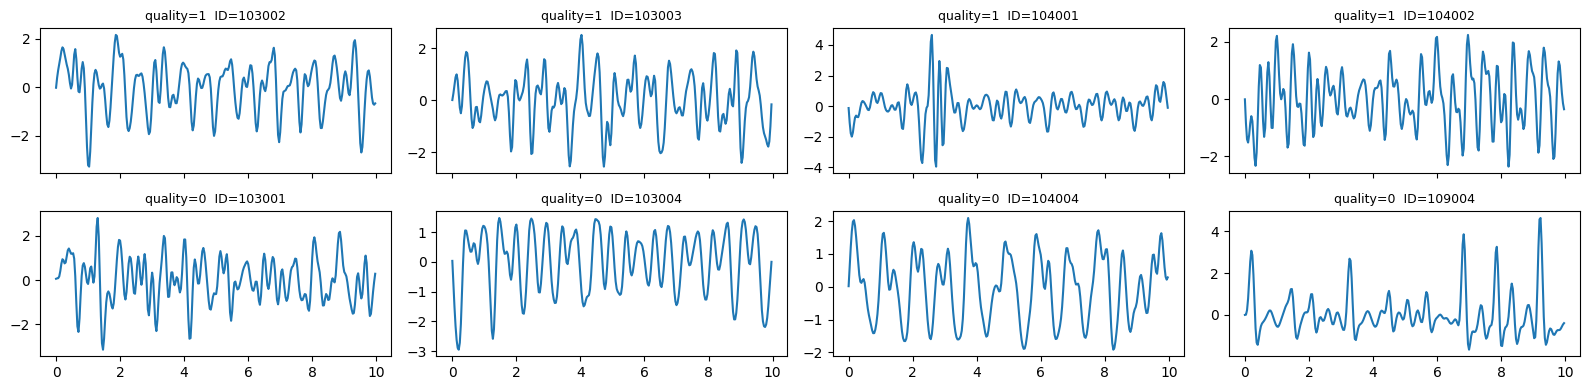

In [ ]:
sub = data.groupby("subject")["quality"].agg(n="size", good_ratio="mean")
print(sub.describe().round(3).loc[["min", "50%", "max"]])

b, a = butter(3, [0.5/(FS/2), 5.0/(FS/2)], btype="band")
def preprocess(x):
    x = np.asarray(x, dtype=np.float64)
    if x.std() < FLAT_STD:                      # 평평한 신호 → 0 신호
        return np.zeros(len(x), dtype=np.float32)
    x = filtfilt(b, a, x - x.mean())
    return ((x - x.mean()) / (x.std() + 1e-8)).astype(np.float32)

raw_std = X_raw.std(1)
flat = raw_std < FLAT_STD
X = np.stack([preprocess(x) for x in X_raw])[:, None, :]      # (N, 1, 300)
assert np.isfinite(X).all(), "전처리 후 NaN/inf 가 있습니다."
print(f"\n평평한 신호: {int(flat.sum())} / {len(flat)}  (라벨 분포: 나쁨 {int((y[flat]==0).sum())}, 좋음 {int((y[flat]==1).sum())})")
print("전부 0 인 입력 행:", int((np.abs(X).sum((1, 2)) == 0).sum()), "→ 평평한 신호 수와 같아야 정상")
print("원본 표준편차(진폭) 평균 — 나쁨: %.2f | 좋음: %.2f" % (raw_std[y == 0].mean(), raw_std[y == 1].mean()))
assert (~flat).sum() > 0.5 * len(flat), "대부분의 신호가 평평합니다. 데이터 읽기를 다시 확인하세요."

t = np.arange(N_SAMPLES) / FS
fig, ax = plt.subplots(2, 4, figsize=(16, 4), sharex=True)
for r, lab in enumerate([1, 0]):
    cand = [i for i in np.where(y == lab)[0] if not flat[i]][:4]
    for c, i in enumerate(cand):
        ax[r, c].plot(t, X[i, 0]); ax[r, c].set_title(f"quality={lab}  ID={data['ID'][i]}", fontsize=9)
plt.tight_layout(); plt.show()

## 4. 모델 · 학습 함수

In [ ]:
class Block(nn.Module):
    def __init__(self, cin, cout, k=5, p=0.15):
        super().__init__()
        self.net = nn.Sequential(nn.Conv1d(cin, cout, k, padding=k//2), nn.BatchNorm1d(cout), nn.ReLU(),
                                 nn.Conv1d(cout, cout, k, padding=k//2), nn.BatchNorm1d(cout), nn.ReLU(),
                                 nn.MaxPool1d(2), nn.Dropout(p))
    def forward(self, x): return self.net(x)

class PPGQualityCNN(nn.Module):                # 입력 (B,1,300) → '좋은 품질' 로짓
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(Block(1, 16), Block(16, 32), Block(32, 64))
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3), nn.Linear(32, 1))
    def forward(self, x): return self.head(self.features(x)).squeeze(-1)

def make_loader(idx, shuffle=False):
    ds = TensorDataset(torch.from_numpy(X[idx]), torch.from_numpy(y[idx].astype(np.float32)))
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, drop_last=bool(shuffle and len(idx) > BATCH))

@torch.no_grad()
def predict(model, idx):
    model.eval(); out = []
    for xb, _ in make_loader(idx):
        out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
    return np.concatenate(out)

def best_threshold(y_true, p):                 # val 에서 '좋음' 클래스 F1 최대 지점
    assert len(set(y_true)) == 2, "val 에 한 클래스만 있어 임계값을 정할 수 없습니다."
    pr, rc, th = precision_recall_curve(y_true, p); f1 = 2*pr*rc/(pr+rc+1e-9)
    return float(th[np.argmax(f1[:-1])])

def split_train_val(idx, n_splits, seed):
    """idx 안에서 피험자 단위로 train/val 분리. val·train 모두 좋음/나쁨이 있는 분할만 사용."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    for a, b_ in sgkf.split(idx, y[idx], groups[idx]):
        if len(set(y[idx][b_])) == 2 and len(set(y[idx][a])) == 2:
            return idx[a], idx[b_]
    raise RuntimeError("좋음/나쁨이 모두 있는 val 분할을 찾지 못했습니다. 데이터 양을 늘리거나 n_splits 를 줄이세요.")

def train_one(tr_idx, va_idx, tag=""):
    torch.manual_seed(SEED)
    model = PPGQualityCNN().to(device)
    pos_w = torch.tensor((1 - y[tr_idx].mean()) / max(y[tr_idx].mean(), 1e-6), device=device, dtype=torch.float32)   # 불균형 보정
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_w)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=4)
    dl = make_loader(tr_idx, True); best, wait, best_state, hist = -1.0, 0, None, {"train_loss": [], "val_auprc": []}
    for ep in range(EPOCHS):
        model.train(); tot = 0.0; seen = 0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            xb = xb + 0.02 * torch.randn_like(xb)                  # 가벼운 노이즈 증강
            opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step(); tot += loss.item() * len(xb); seen += len(xb)
        ap = average_precision_score(y[va_idx], predict(model, va_idx)); sched.step(ap)
        hist["train_loss"].append(tot / max(seen, 1)); hist["val_auprc"].append(float(ap))
        if ap > best: best, wait, best_state = ap, 0, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: break
    if best_state is not None: model.load_state_dict(best_state)
    print(f"{tag} epochs={ep+1} best val AUPRC={best:.4f}")
    return model, hist

## 5. 5-fold 피험자 단위 교차검증
- 각 fold에서 test 피험자는 학습·검증에 전혀 쓰이지 않습니다. (assert 로 확인)
- train 피험자 중 약 20%를 val 로 떼어 early stopping 과 **임계값(F1 최대)** 을 정하고, 그 임계값을 test 에 그대로 적용합니다.
- 비교용 baseline: 단순 통계 특징 6개 + **신호 진폭(log 표준편차)** + 로지스틱 회귀 (같은 분할). CNN 은 z-score 로 진폭을 못 보므로, baseline 이 진폭을 보는 쪽이 더 엄격한 비교입니다.
- **스모크 테스트(SMOKE_TEST=True) 결과 숫자는 해석하지 마세요.** 흐름이 에러 없이 도는지만 보는 용도입니다.

In [ ]:
def baseline_features(x, raw):                 # x: 전처리된 1D 신호, raw: 원본 1D 신호
    amp = np.log1p(raw.std())
    if x.std() < 1e-8:                         # 평평한 신호: 형태 특징은 0, 진폭만 사용
        return [0.0] * 6 + [amp]
    f = np.abs(np.fft.rfft(x))**2; fr = np.fft.rfftfreq(len(x), 1/FS)
    band = (fr >= 0.7) & (fr <= 3.5)
    ac = np.correlate(x, x, "full")[len(x)-1:]; ac = ac / (ac[0] + 1e-12)
    return [skew(x), kurtosis(x), f[band].max()/(f.sum()+1e-9), f[band].sum()/(f.sum()+1e-9), ac[8:45].max(), np.abs(np.diff(x)).mean(), amp]

F = np.array([baseline_features(X[i, 0], X_raw[i]) for i in range(len(X))], dtype=np.float64)
assert np.isfinite(F).all(), f"baseline 특징에 NaN/inf 가 {int((~np.isfinite(F)).sum())}개 있습니다."
print("X:", X.shape, "| F:", F.shape, "| 좋음 비율: %.3f" % y.mean(), "| 피험자:", len(set(groups)), "| F 고유 행 수:", len(np.unique(F.round(6), axis=0)))

n_folds = min(N_FOLDS, len(set(groups)))
skf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
p_cnn = np.zeros(len(y)); p_base = np.zeros(len(y)); thr_cnn = np.zeros(len(y)); thr_base = np.zeros(len(y)); fold_id = np.full(len(y), -1)
split_info, histories = {}, {}

for k, (trval, te) in enumerate(skf.split(X, y, groups)):
    tr, va = split_train_val(trval, 5, SEED + k)
    assert not (set(groups[trval]) & set(groups[te])) and not (set(groups[tr]) & set(groups[va]))
    print(f"[fold {k}] train={len(tr)} val={len(va)} test={len(te)} | test subjects={len(set(groups[te]))} | test good={y[te].mean():.2f}")
    model, histories[k] = train_one(tr, va, f"[fold {k}]")
    p_cnn[te] = predict(model, te); thr_cnn[te] = best_threshold(y[va], predict(model, va))
    clf = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)).fit(F[tr], y[tr])
    p_base[te] = clf.predict_proba(F[te])[:, 1]; thr_base[te] = best_threshold(y[va], clf.predict_proba(F[va])[:, 1])
    fold_id[te] = k
    if p_cnn[te].std() < 1e-4: print(f"  ⚠ fold {k}: CNN 예측이 거의 상수입니다 (std={p_cnn[te].std():.2e})")
    split_info[f"fold{k}"] = {"train_subjects": sorted(set(groups[tr])), "val_subjects": sorted(set(groups[va])), "test_subjects": sorted(set(groups[te]))}

assert (fold_id >= 0).all(), "일부 샘플이 어떤 fold 의 test 에도 들어가지 않았습니다."
assert p_cnn.std() > 1e-4 and p_base.std() > 1e-4, "예측이 상수입니다. 입력 데이터/학습을 다시 확인하세요."
print("\n끝난 fold:", list(split_info.keys()), "→ 모두 완료, 평가 셀을 실행하세요.")

X: (228, 1, 300) | F: (228, 7) | 좋음 비율: 0.263 | 피험자: 12 | F 고유 행 수: 228
[fold 0] train=132 val=48 test=48 | test subjects=2 | test good=0.17
[fold 0] epochs=3 best val AUPRC=0.6563
[fold 1] train=172 val=48 test=8 | test subjects=2 | test good=0.62
[fold 1] epochs=3 best val AUPRC=0.8604
[fold 2] train=152 val=28 test=48 | test subjects=2 | test good=0.21
[fold 2] epochs=3 best val AUPRC=0.7167
[fold 3] train=132 val=48 test=48 | test subjects=2 | test good=0.38
[fold 3] epochs=3 best val AUPRC=0.6972
[fold 4] train=124 val=28 test=76 | test subjects=4 | test good=0.25
[fold 4] epochs=3 best val AUPRC=0.3930

끝난 fold: ['fold0', 'fold1', 'fold2', 'fold3', 'fold4'] → 모두 완료, 평가 셀을 실행하세요.


## 6. 평가

In [ ]:
def metrics(y_true, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)
    two = len(set(y_true)) == 2
    return {"AUROC": roc_auc_score(y_true, p) if two else np.nan, "AUPRC": average_precision_score(y_true, p) if two else np.nan,
            "Acc": accuracy_score(y_true, pred), "BalAcc": balanced_accuracy_score(y_true, pred),
            "Precision(good)": pr, "Recall(good)": rc, "F1(good)": f1,
            "Specificity(bad 걸러냄)": tn/(tn+fp+1e-9), "MCC": matthews_corrcoef(y_true, pred)}

summary = pd.DataFrame({"1D-CNN": metrics(y, p_cnn, thr_cnn), "Baseline(LogReg+진폭)": metrics(y, p_base, thr_base)}).round(4)
print(f"(참고: 항상 '나쁨' 예측 정확도 {(y==0).mean():.3f}, AUPRC 기준선 = 좋음 비율 {y.mean():.3f})")
if SMOKE_TEST: print("※ SMOKE_TEST 결과: 흐름 점검용이므로 숫자를 해석하지 마세요.")
display(summary)

rows = []
for k in range(n_folds):
    m = fold_id == k; r = metrics(y[m], p_cnn[m], thr_cnn[m]); r["fold"] = k; rows.append(r)
cv = pd.DataFrame(rows).set_index("fold"); display(cv.round(4))
print(cv.agg(["mean", "std"]).round(4).loc[["mean", "std"], ["AUROC", "AUPRC", "BalAcc", "F1(good)", "MCC"]])

(참고: 항상 '나쁨' 예측 정확도 0.737, AUPRC 기준선 = 좋음 비율 0.263)
※ SMOKE_TEST 결과: 흐름 점검용이므로 숫자를 해석하지 마세요.


,1D-CNN,Baseline(LogReg+진폭)
AUROC,0.7706,0.7949
AUPRC,0.4991,0.6252
Acc,0.7895,0.7851
BalAcc,0.6857,0.6881
Precision(good),0.6364,0.6170
Recall(good),0.4667,0.4833
F1(good),0.5385,0.5421
Specificity(bad 걸러냄),0.9048,0.8929
MCC,0.4144,0.4095


,AUROC,AUPRC,Acc,BalAcc,Precision(good),Recall(good),F1(good),Specificity(bad 걸러냄),MCC
fold,,,,,,,,,
0,0.9750,0.9187,0.9375,0.8625,0.8571,0.7500,0.8000,0.9750,0.7655
1,0.3333,0.6726,0.3750,0.3000,0.5000,0.6000,0.5455,0.0000,-0.4472
2,0.7553,0.5567,0.7500,0.5842,0.3750,0.3000,0.3333,0.8684,0.1835
3,0.8407,0.7466,0.7917,0.8000,0.6818,0.8333,0.7500,0.7667,0.5830
4,0.7378,0.5357,0.7632,0.5263,1.0000,0.0526,0.1000,1.0000,0.2000


       AUROC   AUPRC  BalAcc  F1(good)     MCC
mean  0.7284  0.6861  0.6146    0.5058  0.2570
std   0.2400  0.1560  0.2256    0.2925  0.4662


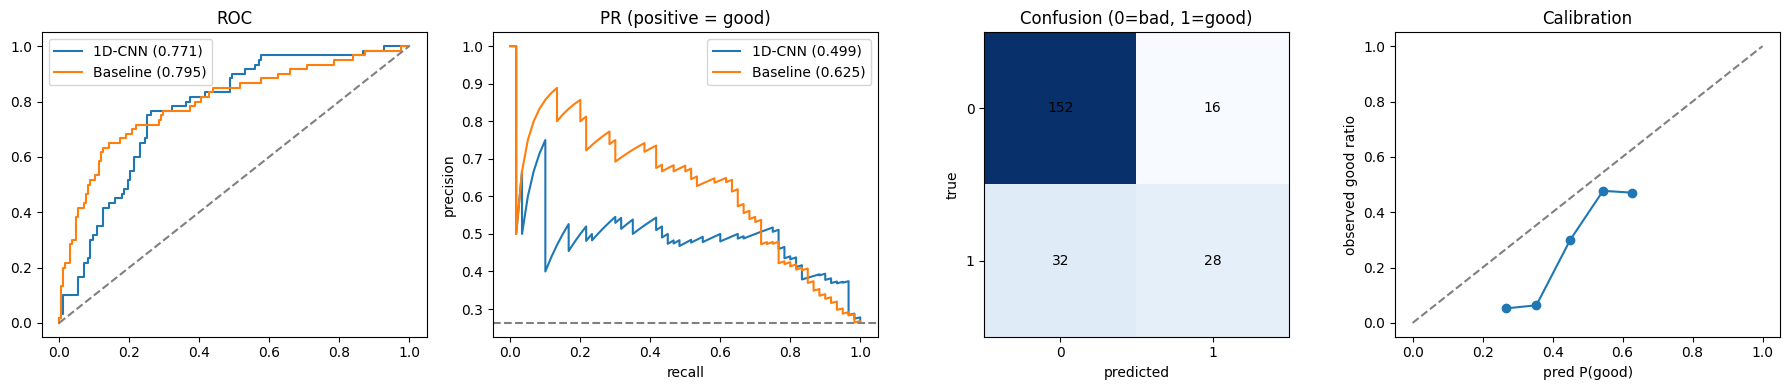

          acc   AUROC
count  12.000  12.000
mean    0.712   0.688
std     0.215   0.279
min     0.250   0.000
25%     0.562   0.660
50%     0.771   0.734
75%     0.844   0.874
max     1.000   1.000


,subject,n,good_ratio,acc,AUROC
1,104,4,0.750,0.250,0.000
2,109,4,0.750,0.500,0.333
9,142,24,0.125,0.708,0.603
5,126,24,0.417,0.583,0.679
6,130,24,0.167,0.833,0.712
10,144,24,0.375,0.750,0.719
0,103,4,0.500,0.500,0.750
11,148,24,0.083,0.917,0.750


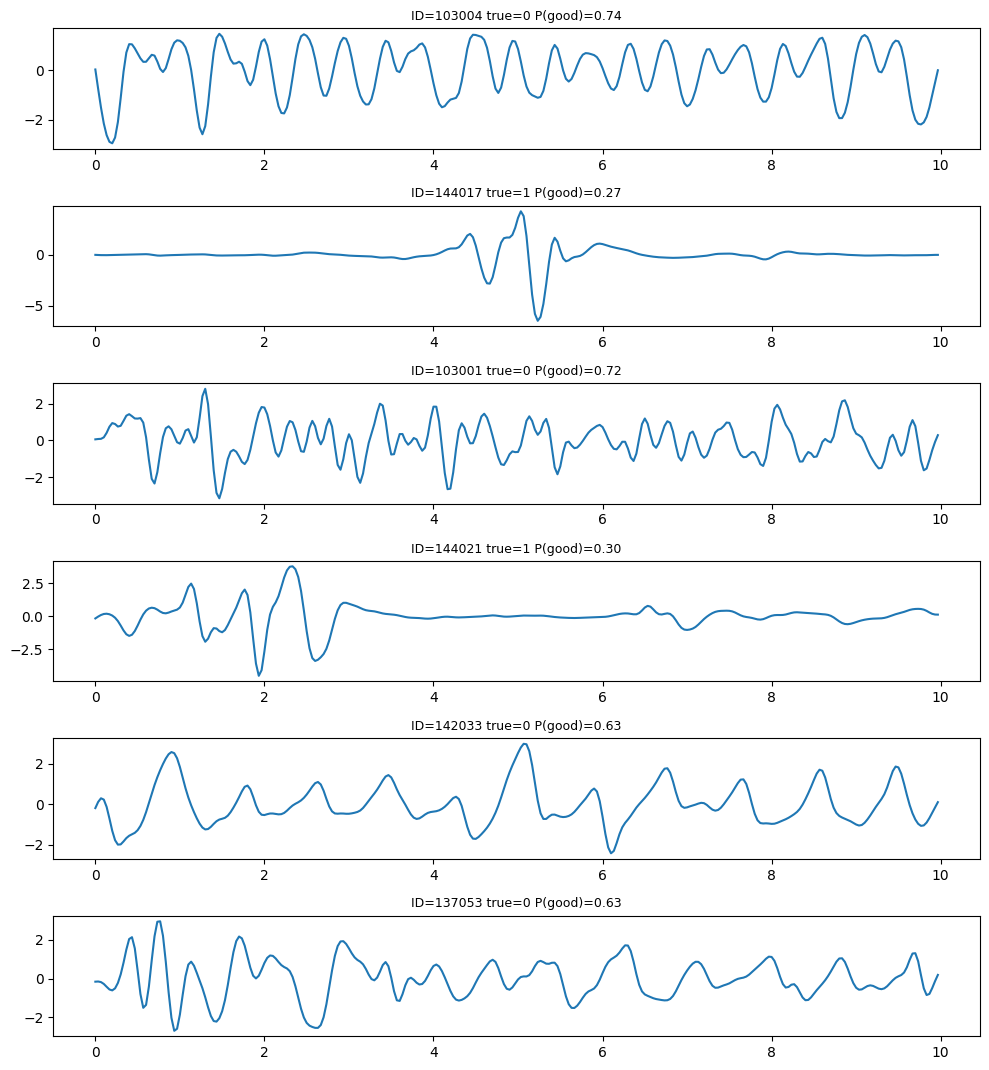

In [ ]:
pred = (p_cnn >= thr_cnn).astype(int)
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for name, p in [("1D-CNN", p_cnn), ("Baseline", p_base)]:
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y, p):.3f})")
    pr_, rc_, _ = precision_recall_curve(y, p); ax[1].plot(rc_, pr_, label=f"{name} ({average_precision_score(y, p):.3f})")
ax[0].plot([0, 1], [0, 1], "--", c="gray"); ax[0].set_title("ROC"); ax[0].legend()
ax[1].axhline(y.mean(), ls="--", c="gray"); ax[1].set_title("PR (positive = good)"); ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].legend()
cm = confusion_matrix(y, pred); ax[2].imshow(cm, cmap="Blues"); ax[2].set_title("Confusion (0=bad, 1=good)")
for i in range(2):
    for j in range(2): ax[2].text(j, i, cm[i, j], ha="center", va="center")
ax[2].set_xticks([0, 1]); ax[2].set_yticks([0, 1]); ax[2].set_xlabel("predicted"); ax[2].set_ylabel("true")
bins = np.linspace(0, 1, 11); bi = np.digitize(p_cnn, bins) - 1
xs = [p_cnn[bi == c].mean() for c in range(10) if (bi == c).sum() > 5]; ys_ = [y[bi == c].mean() for c in range(10) if (bi == c).sum() > 5]
ax[3].plot(xs, ys_, "o-"); ax[3].plot([0, 1], [0, 1], "--", c="gray"); ax[3].set_title("Calibration"); ax[3].set_xlabel("pred P(good)"); ax[3].set_ylabel("observed good ratio")
plt.tight_layout(); plt.show()

# 피험자별 성능
rows = []
for s in sorted(set(groups)):
    m = groups == s
    rows.append({"subject": s, "n": int(m.sum()), "good_ratio": y[m].mean(), "acc": accuracy_score(y[m], pred[m]),
                 "AUROC": roc_auc_score(y[m], p_cnn[m]) if len(set(y[m])) > 1 else np.nan})
subj = pd.DataFrame(rows); print(subj[["acc", "AUROC"]].describe().round(3)); display(subj.sort_values("AUROC").head(8).round(3))

# 가장 확신하며 틀린 예시
wrong = np.where(pred != y)[0]; wrong = wrong[np.argsort(-np.abs(p_cnn[wrong] - y[wrong]))][:6]
if len(wrong):
    fig, axes = plt.subplots(len(wrong), 1, figsize=(10, 1.8 * len(wrong)), squeeze=False)
    for a_, i in zip(axes[:, 0], wrong): a_.plot(t, X[i, 0]); a_.set_title(f"ID={data['ID'][i]} true={y[i]} P(good)={p_cnn[i]:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

## 7. 최종 모델 학습 · 저장 · 추론 예시
- CV 로 성능을 확인한 뒤, **전체 피험자**로 최종 모델을 학습합니다. (피험자 약 15%를 val 로 분리 → early stopping·임계값)
- 저장 위치: `models/but_quality_cnn_v1/` (스모크는 `..._smoke/`) — `best_model.pt`, `config.json`, `metrics.json`, `split.json`, `history.json`, `oof_predictions.csv`
- 이 폴더는 `.gitignore` 대상이 아니므로 커밋하려면 용량(작음)과 라이선스를 확인하세요. `data/raw`·`data/processed` 는 커밋되지 않습니다.

In [ ]:
tr_f, va_f = split_train_val(np.arange(len(y)), 7, SEED)
final_model, final_hist = train_one(tr_f, va_f, "[final]")
final_thr = best_threshold(y[va_f], predict(final_model, va_f))
print(f"최종 임계값(val F1 최대): {final_thr:.3f} | CV fold 임계값 중앙값: {np.median([thr_cnn[fold_id == k][0] for k in range(n_folds)]):.3f}")

os.makedirs(RESULT_DIR, exist_ok=True)
torch.save(final_model.state_dict(), f"{RESULT_DIR}/best_model.pt")
config = {"task": "BUT PPG quality (1=good for HR, 0=bad)", "dataset": "but (PhysioNet butppg 2.0.0)", "fs": FS, "n_samples": N_SAMPLES,
          "channel": CHANNEL_NAME, "bandpass_hz": [0.5, 5.0], "normalize": "per-sample z-score (flat signal std<%g -> zeros)" % FLAT_STD,
          "threshold": final_thr, "model": "PPGQualityCNN(3 blocks, 16-32-64)", "epochs_max": EPOCHS, "batch": BATCH, "lr": LR, "seed": SEED,
          "n_samples_total": int(len(y)), "n_subjects": int(len(set(groups))), "n_header_fixed": int(data["hdr_fixed"].sum()), "smoke_test": SMOKE_TEST}
json.dump(config, open(f"{RESULT_DIR}/config.json", "w"), indent=2, ensure_ascii=False)
json.dump({"pooled_oof": summary.to_dict(), "per_fold": cv.round(4).to_dict(orient="index")}, open(f"{RESULT_DIR}/metrics.json", "w"), indent=2, ensure_ascii=False)
json.dump(split_info, open(f"{RESULT_DIR}/split.json", "w"), indent=2)
json.dump({"folds": histories, "final": final_hist}, open(f"{RESULT_DIR}/history.json", "w"), indent=2)
pd.DataFrame({"ID": data["ID"], "subject": groups, "y": y, "p_cnn": p_cnn, "thr": thr_cnn, "fold": fold_id}).to_csv(f"{RESULT_DIR}/oof_predictions.csv", index=False)
print("저장 완료:", RESULT_DIR)

[final] epochs=3 best val AUPRC=0.9655
최종 임계값(val F1 최대): 0.711 | CV fold 임계값 중앙값: 0.611
저장 완료: /content/drive/MyDrive/Colab Notebooks/capdyssey/models/but_quality_cnn_v1_smoke


In [ ]:
# 새 PPG(30Hz, 300개 값, 빨간 채널 0~255 밝기)에 대한 추론 예시
def predict_quality(ppg_300, model=final_model, thr=final_thr):
    x = preprocess(np.asarray(ppg_300, dtype=np.float32))
    with torch.no_grad():
        p = torch.sigmoid(model.eval()(torch.from_numpy(x)[None, None].to(device))).item()
    return {"p_good": round(p, 4), "label": int(p >= thr)}       # 1 = 심박수 읽기 좋은 품질

rng_ = np.random.default_rng(SEED)
pick = list(rng_.choice(np.where(y == 1)[0], 3, replace=False)) + list(rng_.choice(np.where(y == 0)[0], 3, replace=False))
for i in pick:
    print(f"ID={data['ID'][i]} 정답={y[i]} →", predict_quality(X_raw[i]))

ID=137007 정답=1 → {'p_good': 0.852, 'label': 1}
ID=109001 정답=1 → {'p_good': 0.9085, 'label': 1}
ID=137096 정답=1 → {'p_good': 0.7381, 'label': 1}
ID=118025 정답=0 → {'p_good': 0.5992, 'label': 0}
ID=142033 정답=0 → {'p_good': 0.7962, 'label': 1}
ID=144080 정답=0 → {'p_good': 0.4336, 'label': 0}
